# 01 · Datos y EDA — Amazon Reviews 2023 (Electronics)
Proyecto ML: **Análisis de sentimiento y recuperación semántica en reseñas de electrónica**.

Este notebook:
1. Lee por streaming las primeras ~1,5 M reseñas de Electronics (sin descargar los ~20 GB).
2. Crea la etiqueta de sentimiento desde las estrellas (1–2 neg · 3 neu · 4–5 pos).
3. Saca una **muestra balanceada de 50 000 reseñas** y la guarda en `data/electronics_50k.parquet`.
4. Hace el EDA básico.

Pensado para correr en **Google Colab** (Runtime → Run all). Tarda ~5–10 min según la red.

In [1]:
!pip -q install pandas pyarrow matplotlib seaborn requests

In [2]:
import json, gzip, io, os, re, requests
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

N_LEER   = 1_500_000   # reseñas a leer del inicio del archivo
N_FINAL  = 50_000      # tamaño de la muestra final
SEED     = 42
os.makedirs("data", exist_ok=True)

# Fuente 1: Hugging Face (jsonl sin comprimir). Fuente 2: servidor de UCSD (jsonl.gz).
URLS = [
    ("https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/Electronics.jsonl", False),
    ("https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Electronics.jsonl.gz", True),
]

/Users/laura/Desktop/ml-sentiment-amazon/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [3]:
def leer_stream(url, comprimido, n):
    filas = []
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        raw = r.raw
        raw.decode_content = True
        f = gzip.GzipFile(fileobj=raw) if comprimido else raw
        for i, linea in enumerate(io.TextIOWrapper(f, encoding="utf-8")):
            if i >= n: break
            d = json.loads(linea)
            filas.append({k: d.get(k) for k in
                          ["rating","title","text","asin","parent_asin","helpful_vote","verified_purchase","timestamp"]})
            if i % 250_000 == 0: print(f"{i:,} leídas")
    return pd.DataFrame(filas)

for url, gz in URLS:
    try:
        df_raw = leer_stream(url, gz, N_LEER); print("OK desde", url); break
    except Exception as e:
        print("Falló", url, "→", e)
df_raw.shape

0 leídas
250,000 leídas
500,000 leídas
750,000 leídas
1,000,000 leídas
1,250,000 leídas
OK desde https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/Electronics.jsonl


(1500000, 8)

## Limpieza mínima y etiqueta

In [4]:
df = df_raw.copy()
df["title"] = df["title"].fillna("").str.strip()
df["text"]  = df["text"].fillna("").str.replace(r"<br\s*/?>", " ", regex=True).str.strip()
df["review"] = (df["title"] + ". " + df["text"]).str.strip(". ").str.strip()
df = df[df["review"].str.len() >= 20]                 # fuera reseñas vacías o de 1 palabra
df = df.drop_duplicates(subset=["review"])
df["label"] = pd.cut(df["rating"], bins=[0,2,3,5], labels=["negativo","neutro","positivo"])
df["fecha"] = pd.to_datetime(df["timestamp"], unit="ms")
print(df.shape); df["label"].value_counts()

(1399754, 11)


label
positivo    1093274
negativo     202256
neutro       104224
Name: count, dtype: int64

## Distribución original (antes de balancear)
Importante para la defensa: el dataset real está **muy cargado hacia 5★**.

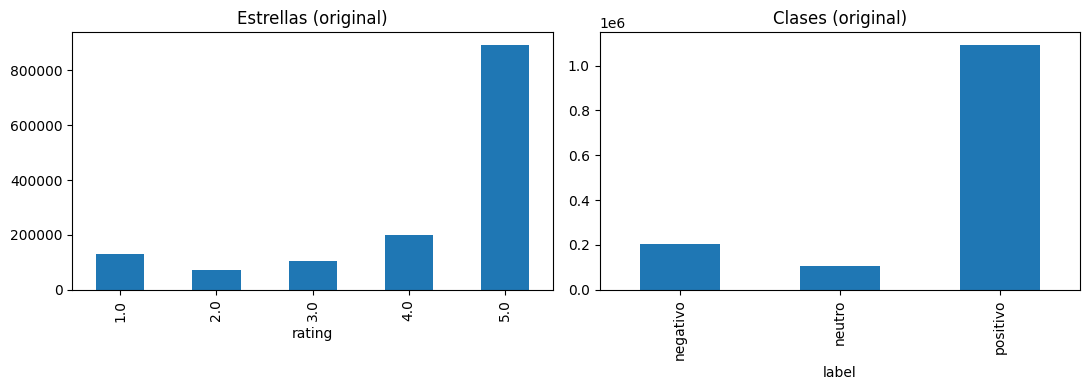

In [5]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
df["rating"].value_counts().sort_index().plot.bar(ax=ax[0], title="Estrellas (original)")
df["label"].value_counts().reindex(["negativo","neutro","positivo"]).plot.bar(ax=ax[1], title="Clases (original)")
plt.tight_layout(); plt.savefig("data/dist_original.png", dpi=120); plt.show()

## Muestra balanceada de 50 000

In [6]:
por_clase = N_FINAL // 3
muestra = pd.concat([g.sample(min(len(g), por_clase), random_state=SEED)
                     for _, g in df.groupby("label", observed=True)])
muestra = muestra.sample(frac=1, random_state=SEED).reset_index(drop=True)
cols = ["review","label","rating","asin","parent_asin","helpful_vote","verified_purchase","fecha"]
muestra[cols].to_parquet("data/electronics_50k.parquet", index=False)
print(muestra.shape); muestra["label"].value_counts()

(49998, 11)


label
negativo    16666
neutro      16666
positivo    16666
Name: count, dtype: int64

## EDA

            count       mean         std  min   25%   50%    75%     max
label                                                                   
negativo  16666.0  72.139866   89.175839  2.0  23.0  45.0  87.00  1624.0
neutro    16666.0  82.609204  109.622273  2.0  25.0  50.0  96.75  2828.0
positivo  16666.0  57.556822   87.953561  2.0  15.0  31.0  65.00  1729.0


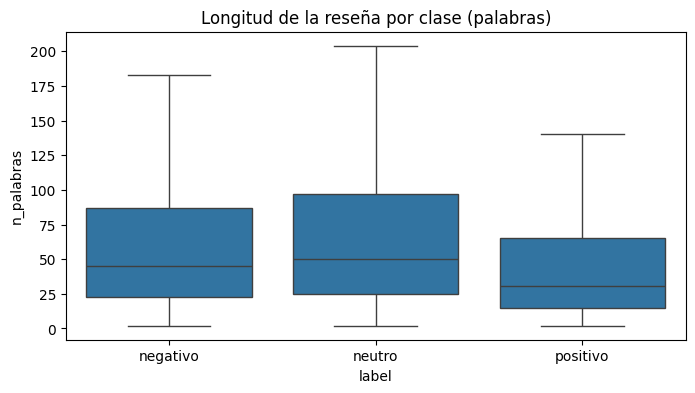

In [7]:
muestra["n_palabras"] = muestra["review"].str.split().str.len()
print(muestra.groupby("label", observed=True)["n_palabras"].describe())
plt.figure(figsize=(8,4))
sns.boxplot(data=muestra, x="label", y="n_palabras", showfliers=False)
plt.title("Longitud de la reseña por clase (palabras)"); plt.savefig("data/longitud.png", dpi=120); plt.show()

In [8]:
from collections import Counter
STOP = set("the a an and or to of is it i this for in on with my was that but have not are be as at so you they its it's very just".split())
def top_palabras(textos, k=15):
    c = Counter(w for t in textos for w in re.findall(r"[a-z']+", t.lower()) if w not in STOP and len(w)>2)
    return c.most_common(k)
for lab in ["negativo","neutro","positivo"]:
    print(lab.upper(), top_palabras(muestra.loc[muestra.label==lab,"review"].head(5000)))

NEGATIVO [('one', 1823), ('work', 1729), ('would', 1390), ('all', 1357), ('had', 1352), ('out', 1339), ('when', 1252), ('get', 1250), ('will', 1205), ('from', 1195), ('after', 1146), ('use', 1099), ('these', 1029), ('only', 1016), ('product', 1014)]
NEUTRO [('good', 1896), ('one', 1795), ('use', 1573), ('when', 1524), ('like', 1485), ('would', 1438), ('out', 1337), ('get', 1322), ('work', 1297), ('had', 1282), ('great', 1241), ('from', 1225), ('will', 1191), ('all', 1181), ('can', 1178)]
POSITIVO [('great', 2836), ('good', 1633), ('works', 1415), ('one', 1312), ('use', 1265), ('well', 1107), ('like', 1100), ('can', 995), ('easy', 931), ('these', 931), ('all', 906), ('from', 897), ('had', 895), ('price', 829), ('quality', 825)]


In [9]:
# Ejemplos para mirar a mano (útiles para la defensa)
for lab in ["negativo","neutro","positivo"]:
    print(f"\n=== {lab} ===")
    for t in muestra.loc[muestra.label==lab,"review"].sample(3, random_state=1): print("-", t[:250])


=== negativo ===
- Low quality unit. The sound quality was very poor (especially when wet) and the Oontz app has to be running on your phone to use Alexa. Which defeats the purpose
- The product arrived damaged and cracked.. This item arrived damaged and cracked. The face plate is cracked that we wanted to use and the quality seems very cheap
- A step up from a Netbook. This laptop was purchased for me as a gift for college. As a rather average college student myself, I thought this laptop would be sufficient for my needs. 4GB RAM is NOT enough - this computer started freezing and crashing 

=== neutro ===
- light but sturdy. I do real estate photography. I first purchased the slik sprint but it was way to light and flimsy - I was afraid to leave my camera on it unattended for even a moment for fear it would tip over- I returned that one and bought the p
- Clean Screen is a Must. Meh - Writing is pretty good, but I have to say that it just isn't convenient enough to replace the old pe

## Notas para la defensa
- El dataset original está desbalanceado (mayoría 5★); se balanceó por submuestreo.
- La etiqueta sale de las estrellas: es una **etiqueta débil** (alguien puede poner 3★ con texto positivo). Esto explica por qué *neutro* será la clase más difícil.
- Siguiente notebook: `02_modelos_sentimiento.ipynb` (TF-IDF + LogReg vs LightGBM/SVM).